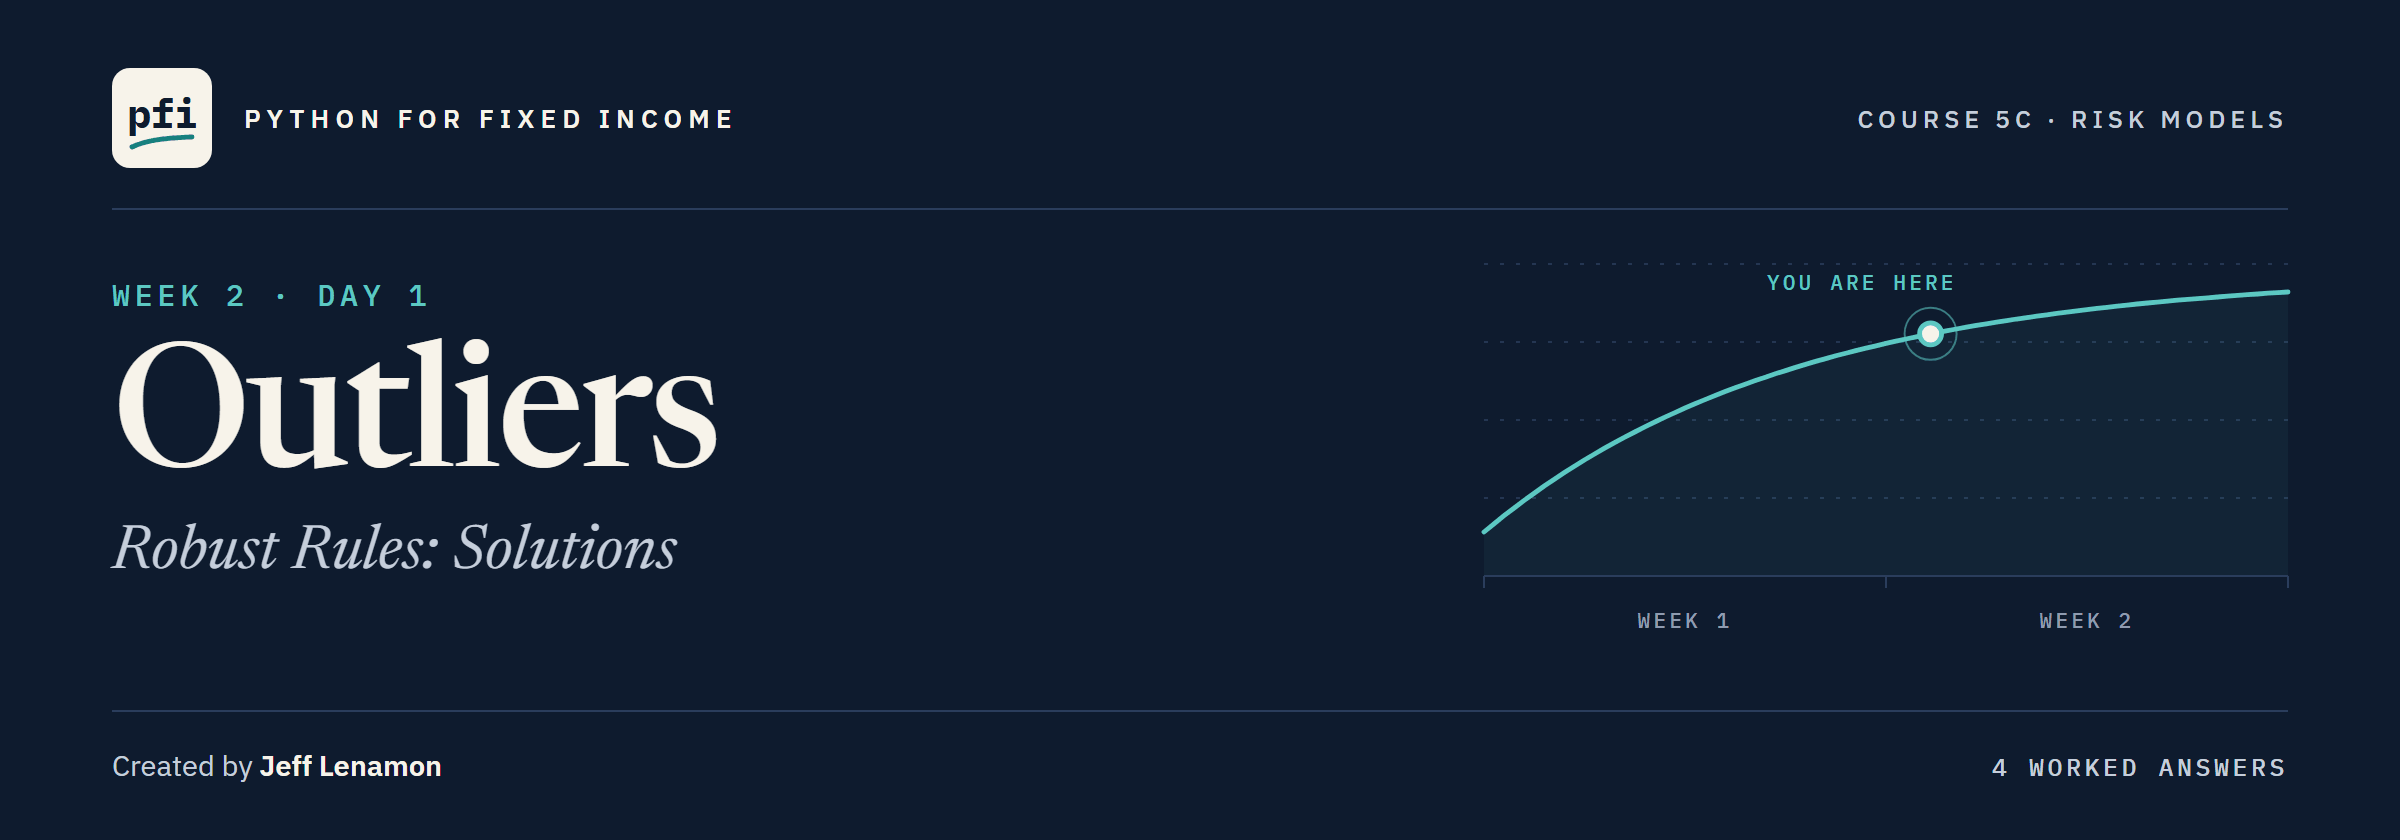

# Outliers: Robust Rules: Solutions

Week 2, Day 1. The full notebook with every exercise worked. Try each one yourself first.

**Data:** `trade_blotter.csv`, the desk's 374 trades in September 2026 in bonds of the book: **synthetic**, invented trades and counterparties.

**Data:** `holdings.csv`, the course's book of 200 bonds as of 2026-09-30, with `ratings.csv` for the rating scale: **synthetic**, invented issuers and CUSIPs, no real company.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course05c_risk_models/week2/day1/06_outliers_robust_rules_solutions.ipynb)

# Problem Statement

## Business Context

A middle office checks the desk's 374 trades of September 2026, in 128 bonds of the book, for prints far from where each bond was trading.
The blotter has no mid column, so the reference is each bond's month-end clean price in the book, as of 2026-09-30.
A flagged trade is a print far from that reference, to be checked: never mispriced, rich or cheap.
To score the screens, 14 bad prints are planted in a copy of the blotter with a seeded generator, and their labels are used only to score.
Today reads only the blotter and the book and fits nothing, so nothing is split: the month is read whole.

## Objectives

Measure each trade's distance from a reference price in points per year of duration.
Plant labelled bad prints in a copy of the blotter with a seeded generator.
Score trades with an ordinary z-score, a z-score built from the median and the MAD, and Tukey's fences.
Test how far one bad print moves each yardstick, and how many it takes to break one.
Score a screen by precision and recall against labels it never saw, and score each trade against the trades before it only.

## Data Dictionary

`trade_blotter.csv`, one row per trade (the columns used today):

1. `trade_id`: T0001 to T0374, in time order
2. `trade_date`, `trade_time`: when the trade printed
3. `cusip`: the bond's identifier (invented)
4. `side`: buy or sell
5. `quantity`: face traded, US$
6. `price`: the clean price printed, per 100 face

`holdings.csv` adds each bond's `issuer`, its `price` (the month-end clean price, per 100 face) and its `duration` (years).

Made in the notebook: `month_end_price`, `points` (the price less the month-end price), `distance` (points per year of duration), `planted`, the scores and the flags.

# Setting Up

## Course Setup

Run this cell and move on: it fixes the seed and finds the course data.

In [1]:
# today's setup: the thread settings, the seed, and where the course data lives
import os
from pathlib import Path

# one thread for the maths libraries, so every run prints the same last digits (this must run before numpy is imported)
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

# the seed: one number for every random choice, so every run makes the same choices
SEED = 42

# the course data: the repo's data folder on your machine, GitHub in Colab
DATA = "../../../data/"
if not Path(DATA + "benchmark.csv").exists():
    DATA = "https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/"

## Importing the Libraries

In [2]:
# to load and work with the data
import numpy as np
import pandas as pd

# the normal curve's percentiles
from scipy import stats

# to score a screen against the planted labels
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score

# to draw charts, and a slider
import matplotlib.pyplot as plt
import seaborn as sns
from ipywidgets import interact

# one look for every chart
sns.set_theme(style="whitegrid")
sns.set_palette("colorblind")
# one colour for each of the four kinds of row a confusion matrix counts
CELL_COLOURS = {"TN": "#56B4E9", "FP": "#DE8F05", "FN": "#D55E00", "TP": "#0173B2"}
plt.rcParams["figure.figsize"] = (10, 5)

# Loading the Data

## Reading the Blotter and the Book

In [3]:
# the desk's 374 synthetic trades of September 2026, and the book of 200 bonds as of 2026-09-30
blotter = pd.read_csv(DATA + "trade_blotter.csv")
book = pd.read_csv(DATA + "holdings.csv")
print("Blotter:", blotter.shape, "| book:", book.shape)

Blotter: (374, 12) | book: (200, 19)


## Adding Each Bond's Month-End Price

In [4]:
# each bond's issuer, month-end clean price and duration from the book, matched on the CUSIP
reference = book[["cusip", "issuer", "price", "duration"]].rename(columns={"price": "month_end_price"})
trades = blotter.merge(reference, on="cusip", how="left")
print("Trades without a reference:", trades["month_end_price"].isna().sum())
print("Same order as the blotter:", trades["trade_id"].equals(blotter["trade_id"]))

Trades without a reference: 0
Same order as the blotter: True


Every trade finds its bond in the book, and the rows keep the blotter's order.

# Data Overview

## Checking the First Five Rows

In [5]:
trades[["trade_id", "trade_date", "trade_time", "issuer", "side", "quantity", "price", "month_end_price", "duration"]].head()

,trade_id,trade_date,trade_time,issuer,side,quantity,price,month_end_price,duration
0,T0001,2026-09-01,08:04,Krilellix Networks,BUY,500000,103.053,102.371,5.180
1,T0002,2026-09-01,09:10,Pellwick Paper,SELL,245000,95.434,95.780,6.779
2,T0003,2026-09-01,09:10,Tovovar Water,BUY,25000,97.875,96.938,6.746
3,T0004,2026-09-01,09:17,Bruxamyth Brands,BUY,750000,102.500,104.788,12.895
4,T0005,2026-09-01,10:05,Thalostrin Finance,BUY,65000,94.233,94.900,5.950


One row a trade: the price printed, and beside it the bond's price at the month's end.

## Missing Values, Trades per Bond and per Day

In [6]:
# missing values, repeated ids, trades per bond and per day, and whether the ids run in time order
per_bond = trades["cusip"].value_counts()
per_day = trades.groupby("trade_date").size()
print("Missing values:", trades.isna().sum().sum(), "| repeated trade ids:", trades["trade_id"].duplicated().sum())
print("Bonds:", len(per_bond), "| trading once:", (per_bond == 1).sum(), "| trades a bond on average:", round(per_bond.mean(), 1))
print("Trading days:", len(per_day), "| trades a day:", per_day.min(), "to", per_day.max())
print("Ids in time order:", trades.sort_values(["trade_date", "trade_time", "trade_id"]).index.equals(trades.index))

Missing values: 0 | repeated trade ids: 0
Bonds: 128 | trading once: 57 | trades a bond on average: 2.9
Trading days: 21 | trades a day: 7 to 29
Ids in time order: True


In [7]:
# a bond-day is one bond on one date: how many hold a single trade
bond_days = trades.groupby(["cusip", "trade_date"]).size()
print("Bond-days:", len(bond_days), "| with one trade:", (bond_days == 1).sum())

Bond-days: 332 | with one trade: 299


57 bonds trade once, and 299 of 332 bond-days hold one trade.

A median of a bond's own prints would mostly be the print itself, so each bond's month-end price is the reference.

The ids run in time order, so a trade's row number is its place in the month.

**A clean month of trades: every print is ordinary until we plant the bad ones.**

# Exploratory Data Analysis

## Distance in Points and per Year of Duration

A long bond's price moves more for the same move in yield (Course 2's duration), so points alone would make long bonds look far away.

In [8]:
# points: how far each trade's price sits from its bond's month-end price, per 100 face; then per year of duration
trades["points"] = trades["price"] - trades["month_end_price"]
trades["distance"] = trades["points"] / trades["duration"]

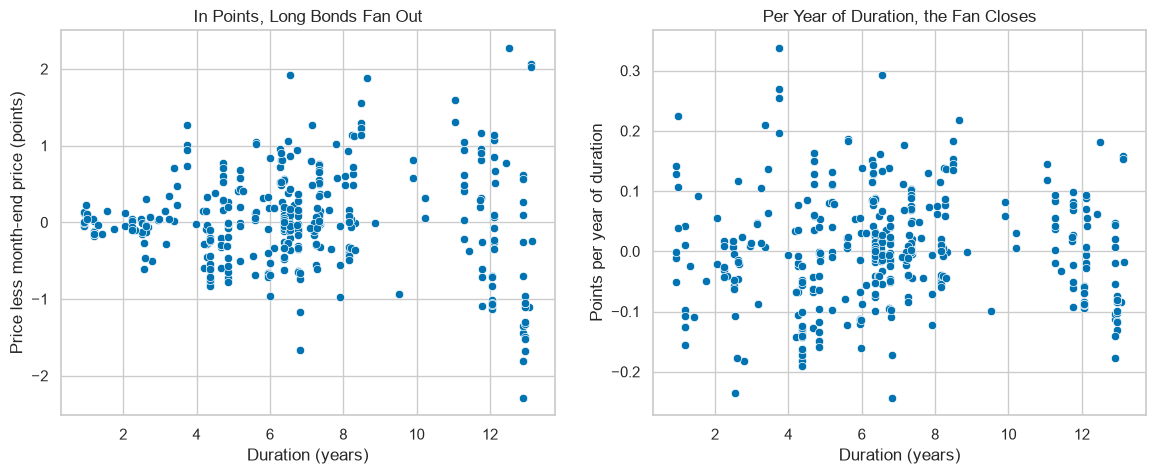

In [9]:
# both measures against duration
fig, (left, right) = plt.subplots(1, 2, figsize=(14, 5), sharex=True)
sns.scatterplot(data=trades, x="duration", y="points", ax=left)
sns.scatterplot(data=trades, x="duration", y="distance", ax=right)
left.set(xlabel="Duration (years)", ylabel="Price less month-end price (points)", title="In Points, Long Bonds Fan Out")
right.set(xlabel="Duration (years)", ylabel="Points per year of duration", title="Per Year of Duration, the Fan Closes")
plt.show()

In [10]:
# the spread of each measure in three duration groups of equal size, and how size goes with duration
thirds = pd.qcut(trades["duration"], 3, labels=["short", "middle", "long"])
print(trades.groupby(thirds)[["points", "distance"]].std().round(3))
print("Correlation of size with duration, in points:", round(trades["points"].abs().corr(trades["duration"]), 3),
      "| per year:", round(trades["distance"].abs().corr(trades["duration"]), 3))

          points  distance
duration                  
short      0.405     0.106
middle     0.507     0.078
long       0.910     0.083
Correlation of size with duration, in points: 0.495 | per year: -0.061


In points the spread more than doubles from short bonds to long ones; per year of duration the three groups sit close together.

Size goes with duration in points (0.495) and barely at all per year (-0.061).

## Distance by Trading Day

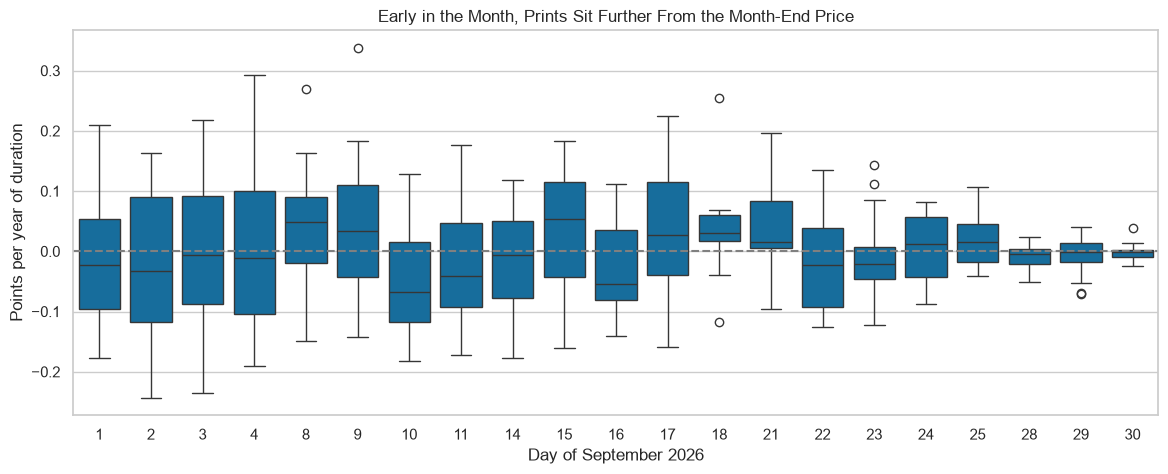

In [11]:
# each trade's distance by its day of September (.dt.day is the day of the month), one box a day
day = pd.to_datetime(trades["trade_date"]).dt.day
plt.figure(figsize=(14, 5))
sns.boxplot(x=day, y=trades["distance"], color="C0")
plt.axhline(0, color="gray", linestyle="--")
plt.xlabel("Day of September 2026")
plt.ylabel("Points per year of duration")
plt.title("Early in the Month, Prints Sit Further From the Month-End Price")
plt.show()

In [12]:
# the spread of the distances week by week (.dt.isocalendar().week numbers the week of the year)
week = pd.to_datetime(trades["trade_date"]).dt.isocalendar().week
trades.groupby(week)["distance"].std().round(3)

week
36    0.120
37    0.109
38    0.093
39    0.067
40    0.024
Name: distance, dtype: float64

Early prints sit further from the month-end price than late ones: the weekly sd falls from 0.120 to 0.024.

The file does not record why.

**We measure every print in points per year of duration from its bond's month-end price, and remember that the spread narrows toward month-end.**

# Planting Bad Prints

## Fourteen Prints in a Copy

`rng.choice(n, k, replace=False)` (Course 4's Day 12) picks k different rows, and `rng.uniform` (Course 4's Day 6) draws each move's size.
Ten prints move 1.5 to 4 points up or down, and four have the decimal point slipped one place.

In [13]:
# one generator for the planting: 14 rows, the first 10 off-market, the last 4 with a slipped decimal
rng = np.random.default_rng(SEED)
rows = rng.choice(len(blotter), 14, replace=False)
off_market, slipped = rows[:10], rows[10:]

In [14]:
# a copy of the blotter: 10 prices moved 1.5 to 4 points up or down, 4 divided by 10
prints = blotter.copy()
moves = rng.choice([-1.0, 1.0], 10) * rng.uniform(1.5, 4.0, 10)
prints.loc[off_market, "price"] = (prints.loc[off_market, "price"] + moves).round(3)
prints.loc[slipped, "price"] = (prints.loc[slipped, "price"] / 10).round(3)

# the labels: a print is planted where the copy's price differs from the file's
planted = prints["price"] != blotter["price"]
print("Planted prints:", planted.sum())

Planted prints: 14


In [15]:
# the 14 planted prints, the true price beside the planted one
planted_table = trades.loc[planted, ["trade_id", "trade_date", "issuer", "duration", "price"]].rename(columns={"price": "true_price"})
planted_table["planted_price"] = prints.loc[planted, "price"]
planted_table["kind"] = np.where(planted_table.index.isin(slipped), "slipped decimal", "off-market")
planted_table

,trade_id,trade_date,issuer,duration,true_price,planted_price,kind
31,T0032,2026-09-02,Delvazor Paper,12.967,102.435,10.244,slipped decimal
32,T0033,2026-09-02,Galvellix Paper,6.506,88.513,91.908,off-market
34,T0035,2026-09-02,Sylvazor Power,8.291,90.744,93.411,off-market
74,T0075,2026-09-08,Krilellix Networks,4.710,109.410,111.296,off-market
158,T0159,2026-09-15,Zephiskan Resources,7.565,94.024,92.414,off-market
159,T0160,2026-09-15,Clavane Foods,11.770,106.702,102.775,off-market
195,T0196,2026-09-16,Lorvellix Energy,8.157,104.313,10.431,slipped decimal
237,T0238,2026-09-21,Vyrellix Telecom,3.737,103.401,105.388,off-market
256,T0257,2026-09-23,Corvamyth Wireless,6.523,101.907,98.174,off-market
274,T0275,2026-09-23,Feskovar Devices,7.252,87.192,83.746,off-market


The planted prints run from 2026-09-02 to 2026-09-30; Lorvellix Energy holds one of each kind.

The copy lives only in this notebook and is never written to disk.

**The labels exist only to score; no threshold today is chosen by looking at them.**

# The Ordinary Z-Score

## The Distances With the Bad Prints In

The z-score (Course 1's Exploratory Data Analysis notebook) is (x - mean) / sd, and a |z| above 3 is the usual flag.

In [16]:
# the same distance, measured on the copy's prices
distance = (prints["price"] - trades["month_end_price"]) / trades["duration"]

**Predict 1**

Fourteen bad prints sit among 374 trades, four of them a tenth of their true price.

Q. How many trades have a z-score above 3 in absolute value? Write down a number.

## Flags at Three Standard Deviations

In [17]:
# every print's z-score, and the trades beyond 3 standard deviations
z = (distance - distance.mean()) / distance.std()
print("Mean:", round(distance.mean(), 4), "| standard deviation:", round(distance.std(), 4))
print("Trades with |z| above 3:", (z.abs() > 3).sum(), prints.loc[z.abs() > 3, "trade_id"].tolist())

Mean: -0.3398 | standard deviation: 5.1676
Trades with |z| above 3: 1 ['T0281']


In [18]:
# the band the z-score draws, mean plus or minus 3 sd, beside the range of the ordinary prints
z_low, z_high = distance.mean() - 3 * distance.std(), distance.mean() + 3 * distance.std()
print("z band:", round(z_low, 2), "to", round(z_high, 2), "points per year")
print("Ordinary prints:", round(distance[~planted].min(), 2), "to", round(distance[~planted].max(), 2))

z band: -15.84 to 15.16 points per year
Ordinary prints: -0.24 to 0.34


One trade is flagged, out of 14 planted.

The band is more than fifty times as wide as the range the ordinary prints fill.

## How Far the Bad Prints Stretched the Yardstick

In [19]:
# the standard deviation with the planted prints, without them, and with T0281 alone added back; the off-market z
print("With the planted prints:", round(distance.std(), 4))
print("The 360 ordinary prints:", round(distance[~planted].std(), 4), "| times smaller:", round(distance.std() / distance[~planted].std()))
alone = ~planted | (prints["trade_id"] == "T0281")
print("Ordinary prints plus T0281 alone:", round(distance[alone].std(), 2))
print("Off-market z:", z[off_market].min().round(2), "to", z[off_market].max().round(2))

With the planted prints: 5.1676
The 360 ordinary prints: 0.0899 | times smaller: 57
Ordinary prints plus T0281 alone: 5.18
Off-market z: -0.05 to 0.21


T0281, a Veyrholt Health bond of 0.93 years printed at 10.134 for 101.337, takes the sd to 5.18 by itself.

The off-market prints, 1.5 to 4 points away, score z between -0.05 and 0.21: they hide in plain sight.

This is **masking**: bad values stretch the yardstick that should catch them.

In [20]:
# a demonstration with the labels, which show the effect and choose nothing: drop the 4 slipped prints, score again at 3
kept = distance.drop(slipped)
kept_z = (kept - kept.mean()) / kept.std()
print("Flags:", (kept_z.abs() > 3).sum(), "| off-market prints among them:", ((kept_z.abs() > 3) & planted.drop(slipped)).sum(), "of 10")

Flags: 8 | off-market prints among them: 8 of 10


Without the slipped decimals the same rule finds 8 of the 10 off-market prints.

A real blotter carries no labels, so this is shown once and never used as a method.

![Two rulers on one axis of points per year of duration from -1 to 1. Top, dashed: the sd of all 374 prints is 5.17, longer than the whole window, its 3 sd fences at -15.8 and 15.2. Bottom: the sd of the 360 ordinary prints is 0.09, a tick per sd, its 3 sd fences as teal bars. The 10 off-market prints sit as dots above both, 8 of them outside the bottom ruler's fences](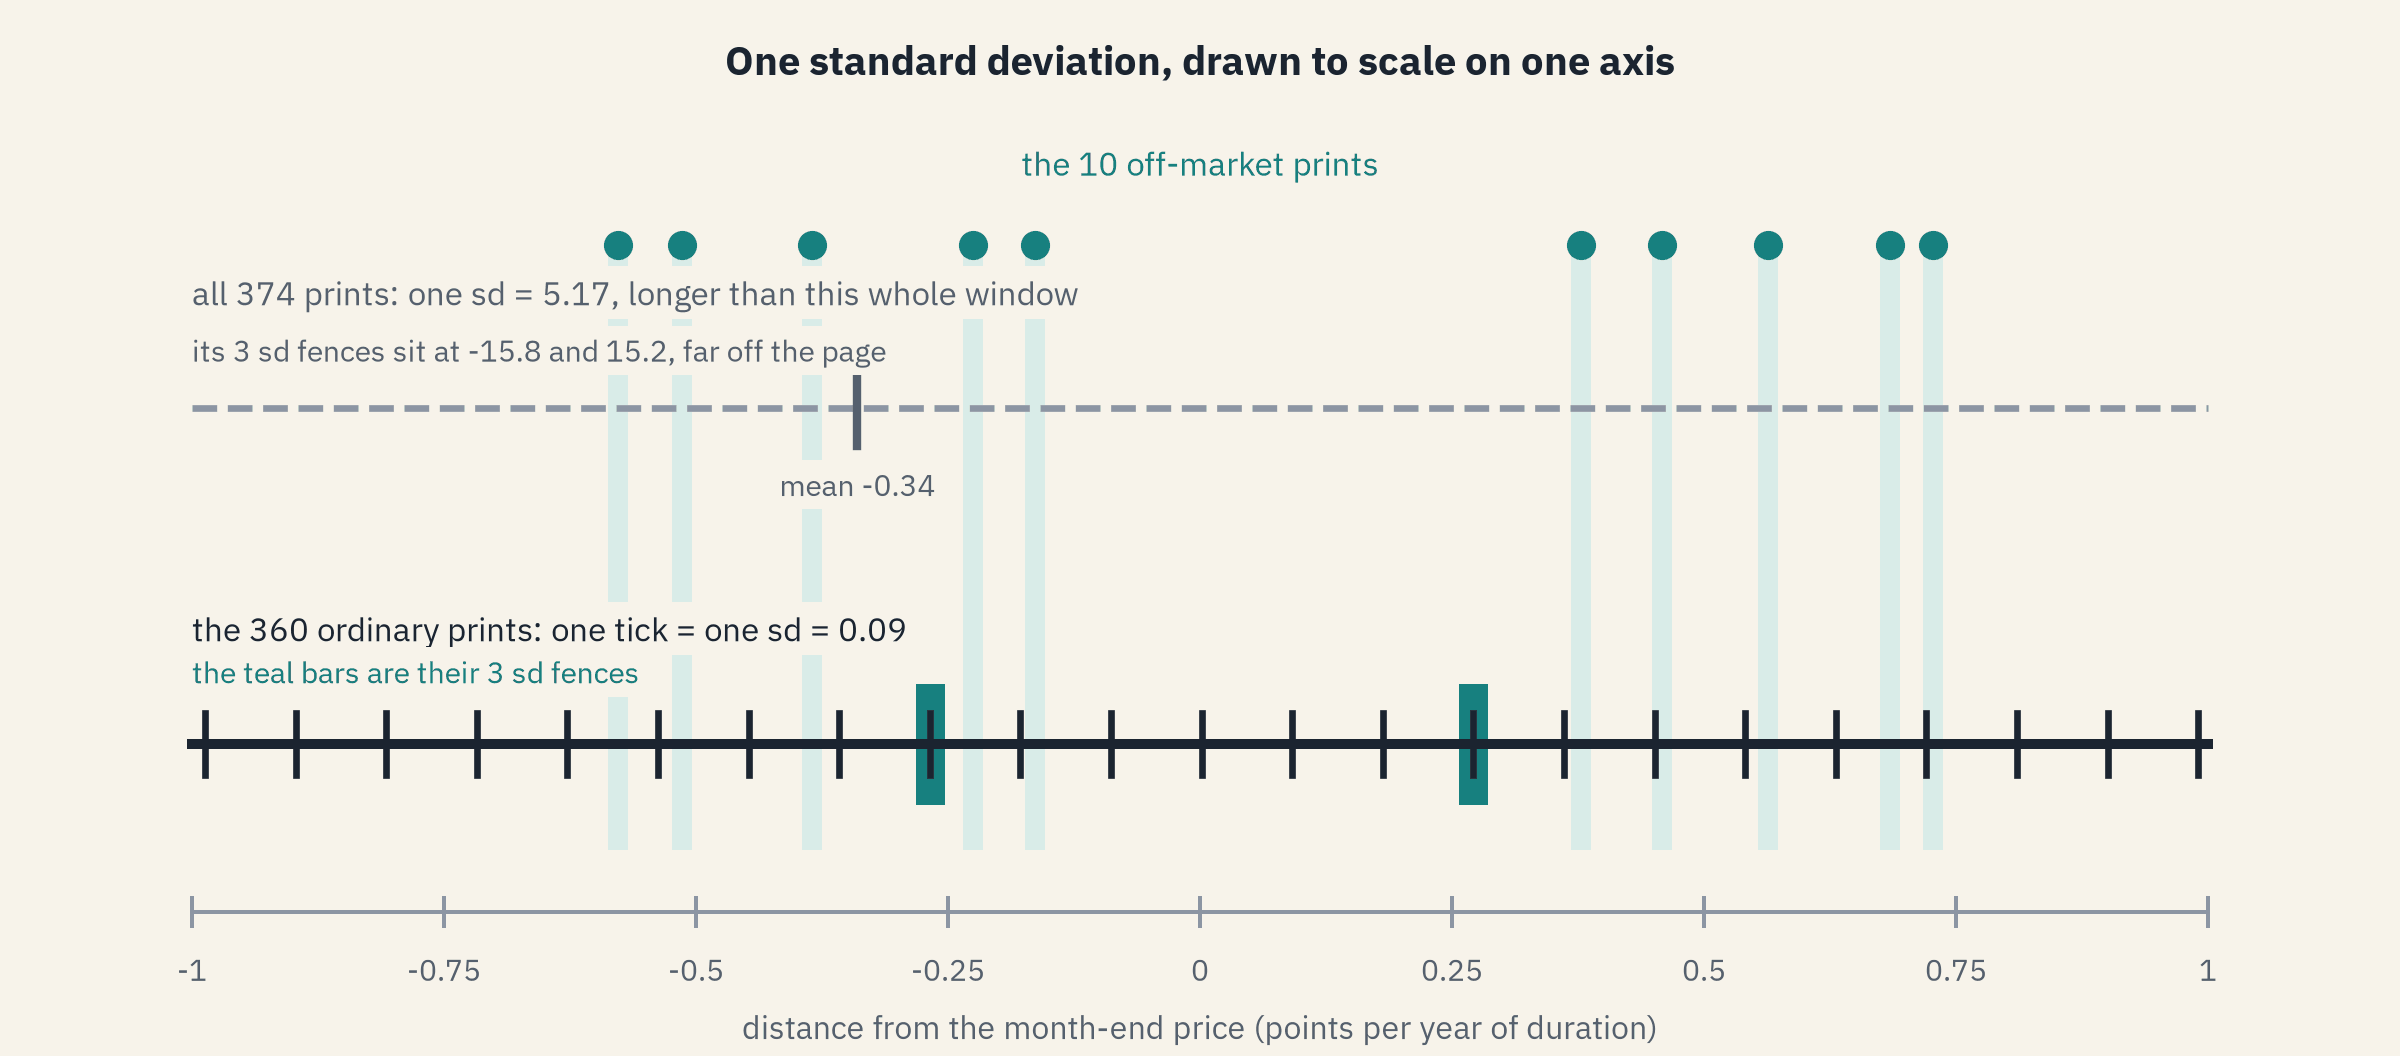)

Measured with the ordinary prints' own yardstick, 8 of the off-market prints sit outside its fences.

**A yardstick made from every print is stretched by the bad ones.**

# The Median and the MAD

## The Median Absolute Deviation

The median (Course 1) is the middle value.
The **median absolute deviation (MAD)** is the median of each value's distance from the median.

In [21]:
# the median and the MAD of the first five trades' distances, step by step
five = trades["distance"].head(5)
gaps = (five - five.median()).abs()
print("Distances:", five.round(3).tolist())
print("Median:", round(five.median(), 3), "| gaps from it:", gaps.round(3).tolist(), "| MAD:", round(gaps.median(), 3))

Distances: [0.132, -0.051, 0.139, -0.177, -0.112]
Median: -0.051 | gaps from it: [0.183, 0.0, 0.19, 0.126, 0.061] | MAD: 0.126


## Scaling the MAD

On a normal curve the middle half lies within 0.6745 sd of the centre, so the MAD of normal data is 0.6745 sd.
Dividing by 0.6745, or multiplying by 1.4826, puts the MAD on the sd's scale: the **scaled MAD**.
`stats.norm.ppf(0.75)` (Day 1) gives the 0.6745.

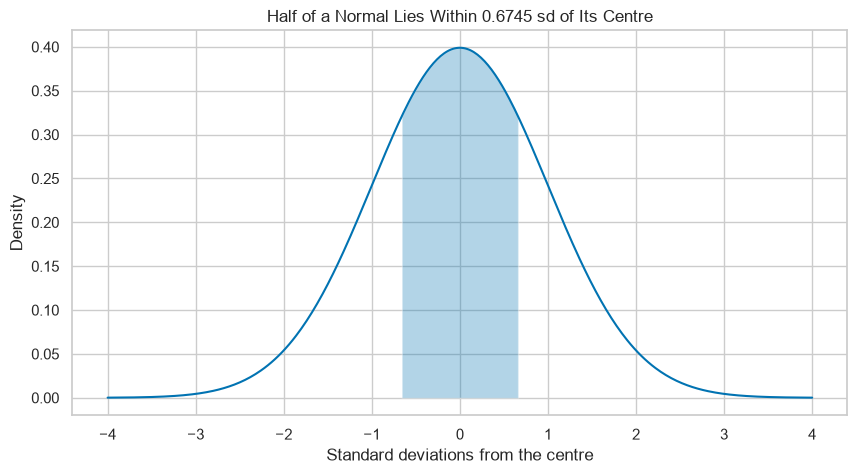

Quartile: 0.6745 | scale, 1 / quartile: 1.4826


In [22]:
# the normal curve with its middle half shaded, and the scale that turns a MAD into an sd
quartile = stats.norm.ppf(0.75)
x = np.linspace(-4, 4, 401)
plt.plot(x, stats.norm.pdf(x))
plt.fill_between(x, stats.norm.pdf(x), where=np.abs(x) <= quartile, alpha=0.3)
plt.xlabel("Standard deviations from the centre")
plt.ylabel("Density")
plt.title("Half of a Normal Lies Within 0.6745 sd of Its Centre")
plt.show()
print("Quartile:", round(quartile, 4), "| scale, 1 / quartile:", round(1 / quartile, 4))

**Predict 2**

Take the untouched month's 374 distances and add one more print, then slide it from -2 to +2 points per year.

Q. Sketch four lines against where the print sits: the mean, the median, the sd and the scaled MAD.

## One Print Slides Along the Line

In [23]:
# the untouched month's distances plus one print, slid from -2 to +2 points per year
clean = trades["distance"]
results = []
for position in np.linspace(-2, 2, 81):
    values = pd.concat([clean, pd.Series([position])], ignore_index=True)
    results.append({"position": position, "mean": values.mean(), "median": values.median(),
                    "sd": values.std(), "scaled MAD": 1.4826 * (values - values.median()).abs().median()})
slide = pd.DataFrame(results)

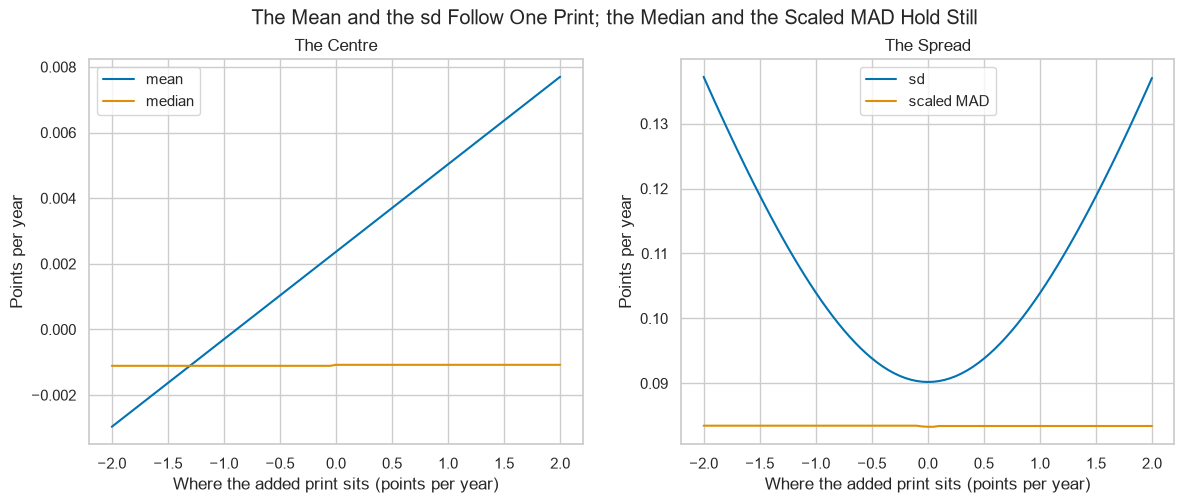

In [24]:
# the centre and the spread as the print slides
fig, (left, right) = plt.subplots(1, 2, figsize=(14, 5), sharex=True)
left.plot(slide["position"], slide[["mean", "median"]], label=["mean", "median"])
right.plot(slide["position"], slide[["sd", "scaled MAD"]], label=["sd", "scaled MAD"])
left.set(xlabel="Where the added print sits (points per year)", ylabel="Points per year", title="The Centre")
right.set(xlabel="Where the added print sits (points per year)", ylabel="Points per year", title="The Spread")
left.legend()
right.legend()
fig.suptitle("The Mean and the sd Follow One Print; the Median and the Scaled MAD Hold Still")
plt.show()

In [25]:
# the slide's two ends and its middle, then one print at -100, the size of a slipped decimal
print(slide.iloc[[0, 40, 80]].round(4))
far = pd.concat([clean, pd.Series([-100.0])], ignore_index=True)
print("At -100: sd", round(far.std(), 4), "| median", round(far.median(), 4), "| scaled MAD", round(1.4826 * (far - far.median()).abs().median(), 4))

    position    mean  median      sd  scaled MAD
0       -2.0 -0.0030 -0.0011  0.1372      0.0835
40       0.0  0.0024 -0.0011  0.0902      0.0833
80       2.0  0.0077 -0.0011  0.1370      0.0834
At -100: sd 5.1649 | median -0.0011 | scaled MAD 0.0835


### Interpretation of the Sensitivity Curves

A **sensitivity curve** shows how far one value moves a measure.

The sd climbs from 0.0902 to 0.137 as the print slides 2 away, and reaches 5.1649 at -100: it grows without bound.

The median and the scaled MAD barely move, whatever the print does.

## Robust Z-Scores at 3.5

The **robust z-score** is (x - median) / scaled MAD.
A |robust z| above 3.5 is the published rule in the story below, written down before any label is read.

In [26]:
# the copy's median, MAD and scaled MAD, in points per year of duration
median = distance.median()
mad = (distance - median).abs().median()
scaled_mad = 1.4826 * mad
print("Median:", round(median, 4), "| MAD:", round(mad, 4), "| scaled MAD:", round(scaled_mad, 4))
print("sd of the 360 ordinary prints, for comparison:", round(distance[~planted].std(), 4))

Median: -0.0012 | MAD: 0.0598 | scaled MAD: 0.0887
sd of the 360 ordinary prints, for comparison: 0.0899


In [27]:
# every print's robust z-score, the flags above 3.5, and the band the rule draws
robust_z = (distance - median) / scaled_mad
robust_flags = robust_z.abs() > 3.5
robust_low, robust_high = median - 3.5 * scaled_mad, median + 3.5 * scaled_mad
print("Flags:", robust_flags.sum(), "| planted among them:", (robust_flags & planted).sum())
print("Robust band:", round(robust_low, 3), "to", round(robust_high, 3), "points per year")

Flags: 13 | planted among them: 12
Robust band: -0.312 to 0.309 points per year


In [28]:
# the one ordinary trade the robust z flags
trades.loc[robust_flags & ~planted, ["trade_id", "trade_date", "issuer", "duration", "points", "distance"]]

,trade_id,trade_date,issuer,duration,points,distance
101,T0102,2026-09-09,Vyrellix Telecom,3.737,1.263,0.337972


With every bad print in, the scaled MAD (0.0887) stays close to the ordinary prints' sd (0.0899).

13 flags, 12 of them planted.

T0102 is an ordinary trade on 2026-09-09, early in the month, 1.263 points from its month-end price: a print to check, and the file does not record why.

## Two Yardsticks on One Month

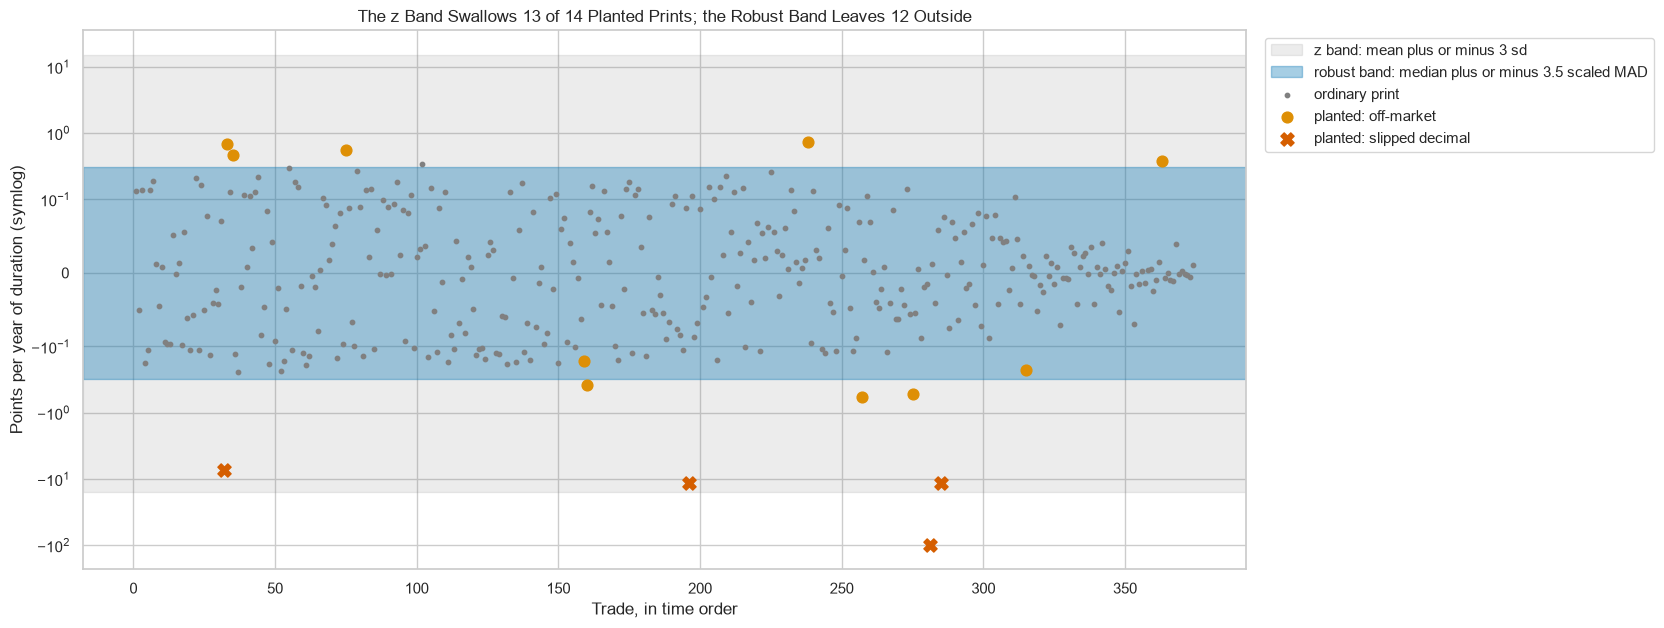

In [29]:
# every print in time order on a symlog axis (straight within 0.1 of zero, logarithmic beyond), inside both bands
trade_number = np.arange(1, len(prints) + 1)
fig, ax = plt.subplots(figsize=(15, 7))
ax.axhspan(z_low, z_high, color="gray", alpha=0.15, label="z band: mean plus or minus 3 sd")
ax.axhspan(robust_low, robust_high, color="C0", alpha=0.35, label="robust band: median plus or minus 3.5 scaled MAD")
ax.scatter(trade_number[~planted], distance[~planted], s=10, color="gray", label="ordinary print")
ax.scatter(trade_number[off_market], distance[off_market], s=60, color="C1", label="planted: off-market")
ax.scatter(trade_number[slipped], distance[slipped], s=90, marker="X", color="C3", label="planted: slipped decimal")
ax.set_yscale("symlog", linthresh=0.1)
ax.set(xlabel="Trade, in time order", ylabel="Points per year of duration (symlog)", title="The z Band Swallows 13 of 14 Planted Prints; the Robust Band Leaves 12 Outside")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.show()

13 of 14 planted prints sit inside the z band, which reaches past -15 and 15.

The robust band runs from -0.312 to 0.309, and only one ordinary print sits outside it.

> STORY: The NIST/SEMATECH e-Handbook of Statistical Methods gives the rule in its section on detecting outliers.
> It writes Iglewicz and Hoaglin's modified Z-score as 0.6745 (x - median) / MAD, the robust z-score of this notebook, since 0.6745 is 1 / 1.4826.
> "These authors recommend that modified Z-scores with an absolute value of greater than 3.5 be labeled as potential outliers."
> The same page warns that "Masking can occur when we specify too few outliers in the test."
> Source: NIST/SEMATECH e-Handbook of Statistical Methods, section 1.3.5.17, "Detection of Outliers", https://www.itl.nist.gov/div898/handbook/eda/section3/eda35h.htm

**The median and the MAD hardly notice the bad prints, so the bad prints stand out.**

# Tukey's Fences

## The Quartile Yardstick

Course 1's box plot reaches its whiskers no further than 1.5 IQR beyond the quartiles.
Used as a screen, the lines 1.5 IQR beyond the quartiles are Tukey's **inner fences**; 3 IQR out are the **outer fences**.

In [30]:
# the quartiles, the IQR, and the prints outside each pair of fences
q1, q3 = distance.quantile([0.25, 0.75])
iqr = q3 - q1
inner_flags = (distance < q1 - 1.5 * iqr) | (distance > q3 + 1.5 * iqr)
outer_flags = (distance < q1 - 3 * iqr) | (distance > q3 + 3 * iqr)
print("Q1:", round(q1, 4), "| Q3:", round(q3, 4), "| IQR:", round(iqr, 4))
print("Outside the inner fences:", inner_flags.sum(), "| outside the outer fences:", outer_flags.sum())

Q1: -0.0606 | Q3: 0.0584 | IQR: 0.119
Outside the inner fences: 17 | outside the outer fences: 10


![A number line of points per year of duration from -0.5 to 0.5. A box from Q1 -0.0606 to Q3 0.0584, the IQR 0.1190; the inner fences as solid lines at -0.2391 and 0.2369, the outer fences dashed at -0.4176 and 0.4154. Beneath, to the same scale, the robust band from -0.312 to 0.309](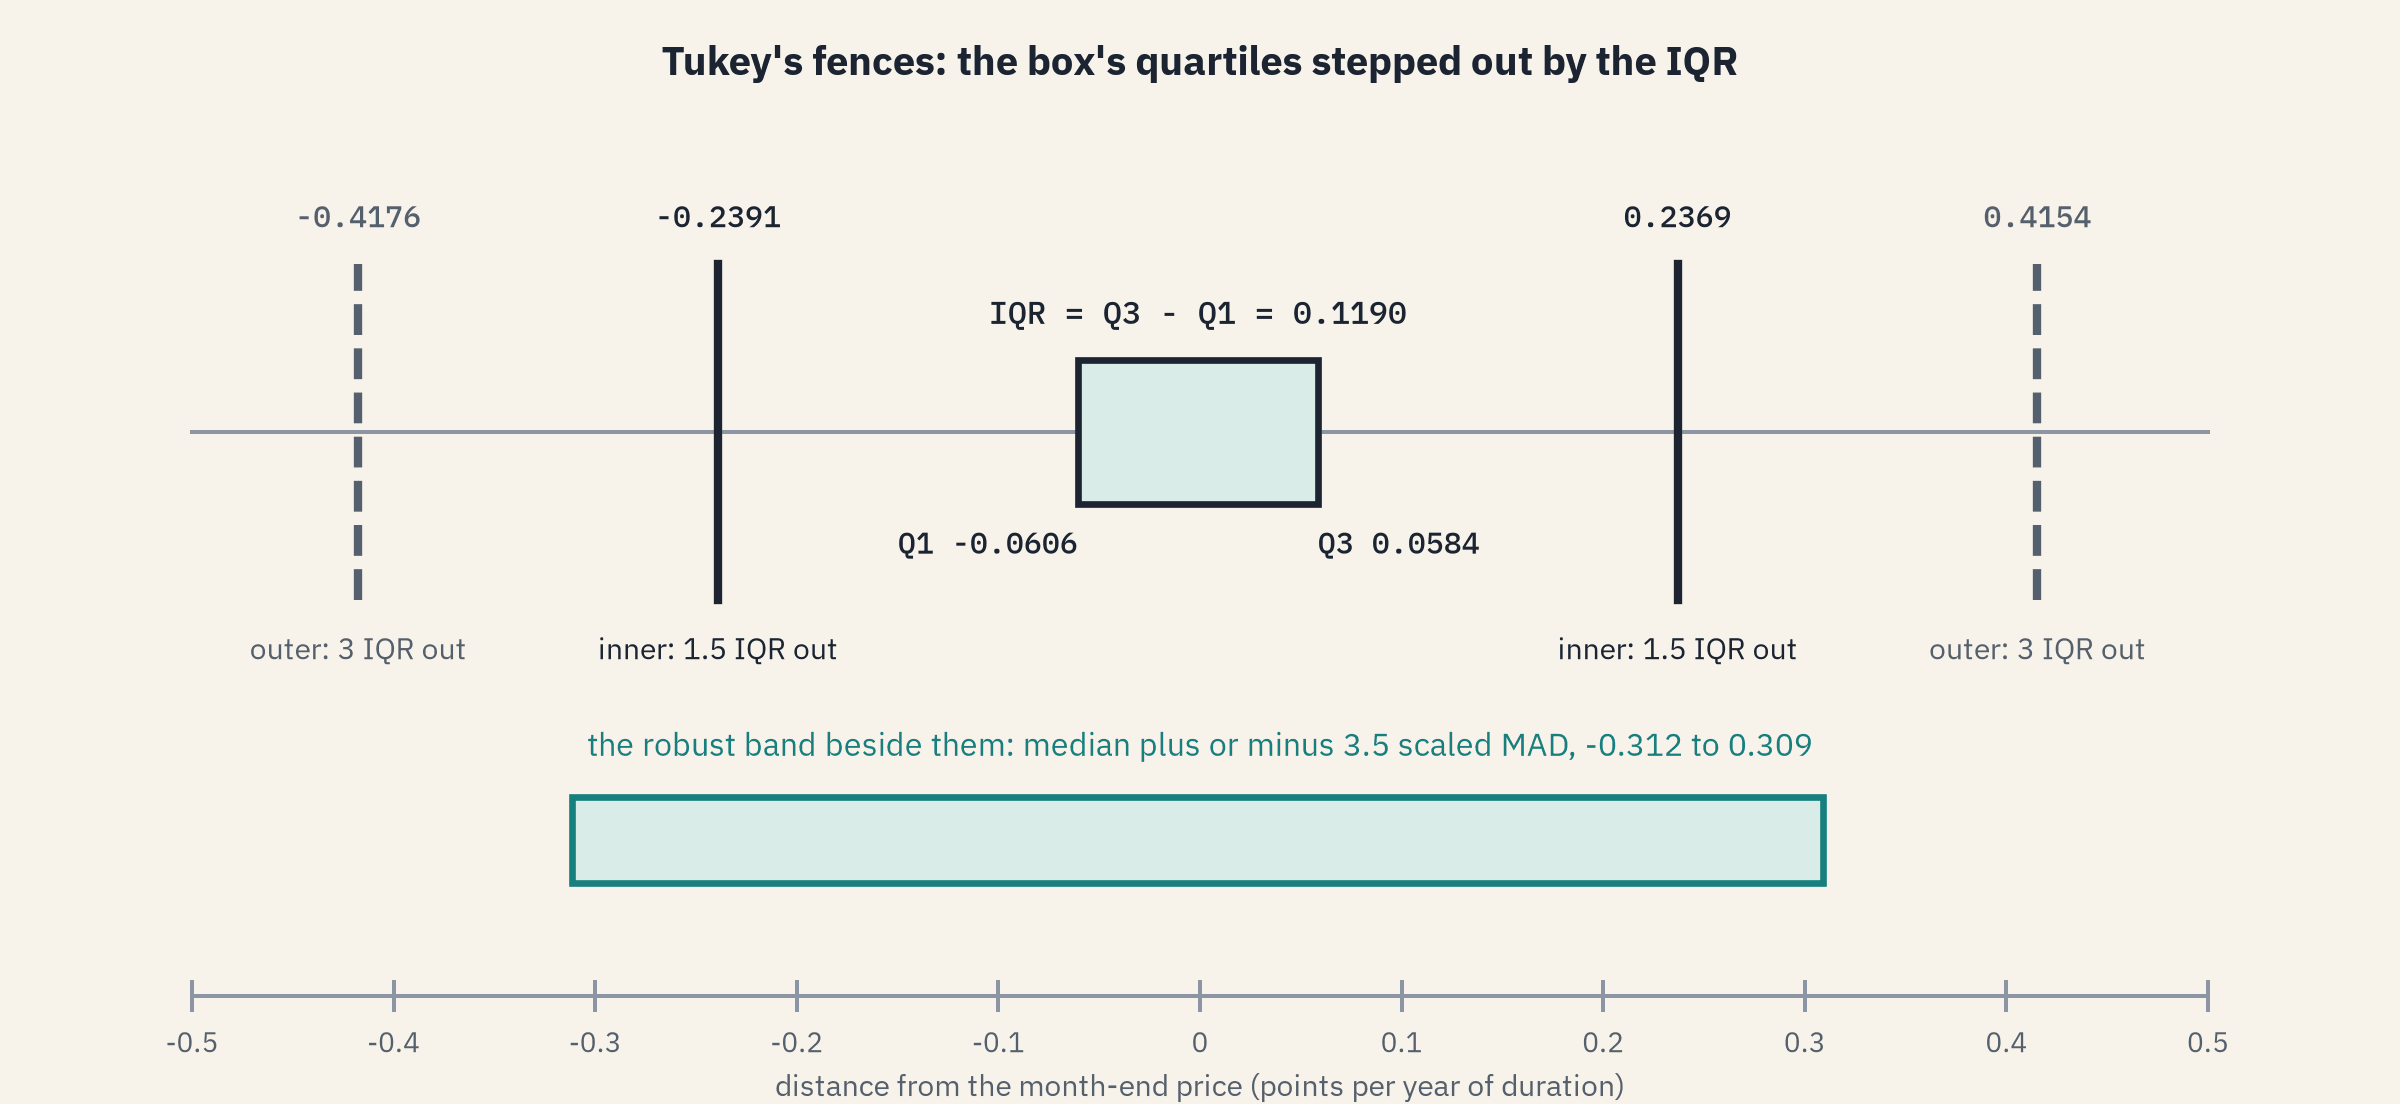)

The robust band sits between the inner and the outer fences.

## How Many Bad Prints Each Yardstick Can Take

A yardstick's **breakdown point** is the share of values that can be replaced by anything before it runs off without bound.
The IQR of a normal is 1.349 sd, so IQR / 1.349 is on the sd's scale.
`rng.permutation(n)` (Course 4's Day 3) shuffles the positions 0 to n - 1.

In [31]:
# a demonstration with its own generator: replace k untouched distances by -10, for k from 0 to 200
rng = np.random.default_rng(SEED)
replace_order = rng.permutation(len(clean))
results = []
for k in range(201):
    values = clean.to_numpy(copy=True)
    values[replace_order[:k]] = -10.0
    values = pd.Series(values)
    results.append({"share": k / len(clean), "sd": values.std(), "IQR / 1.349": (values.quantile(0.75) - values.quantile(0.25)) / 1.349,
                    "scaled MAD": 1.4826 * (values - values.median()).abs().median()})
breakdown = pd.DataFrame(results)

In [32]:
# the first k at which each yardstick passes 1 point per year, about ten times its size on the untouched month
for name in ["sd", "IQR / 1.349", "scaled MAD"]:
    first_k = (breakdown[name] > 1).idxmax()
    print(name, "passes 1 at k =", first_k, f"({first_k / len(clean):.1%} of the values)")
print("sd after one value replaced:", round(breakdown.loc[1, "sd"], 3))

sd passes 1 at k = 4 (1.1% of the values)
IQR / 1.349 passes 1 at k = 94 (25.1% of the values)
scaled MAD passes 1 at k = 187 (50.0% of the values)
sd after one value replaced: 0.525


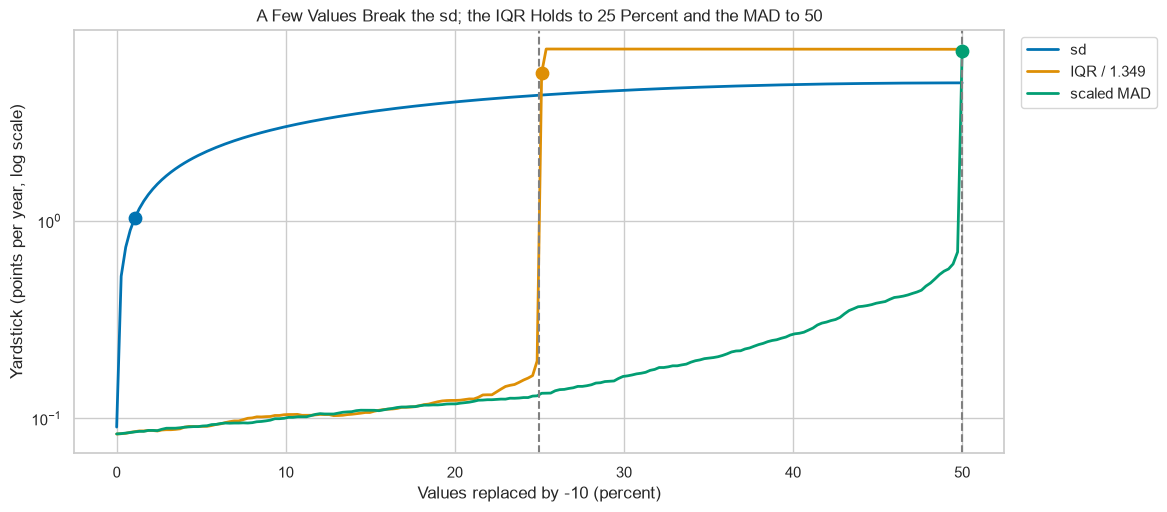

In [33]:
# the three yardsticks against the share replaced, up to half, on a log axis; each one's first k past 1 marked
shown = breakdown[breakdown["share"] <= 0.5]
fig, ax = plt.subplots(figsize=(12, 5.5))
for name in ["sd", "IQR / 1.349", "scaled MAD"]:
    ax.plot(shown["share"] * 100, shown[name], label=name, linewidth=2)
    first_k = (breakdown[name] > 1).idxmax()
    ax.scatter(breakdown.loc[first_k, "share"] * 100, breakdown.loc[first_k, name], s=80, zorder=3)
for share in [25, 50]:
    ax.axvline(share, color="gray", linestyle="--")
ax.set_yscale("log")
ax.set(xlabel="Values replaced by -10 (percent)", ylabel="Yardstick (points per year, log scale)",
       title="A Few Values Break the sd; the IQR Holds to 25 Percent and the MAD to 50")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.show()

One replaced value takes the sd from 0.090 to 0.525, and four take it past 1.

IQR / 1.349 holds until a quarter of the values are replaced, the scaled MAD until half.

**Two yardsticks the bad prints cannot stretch; which screen finds more, and at what cost, needs a score.**

# Scoring the Screens

## Precision and Recall Against the Planted Labels

Course 4's Day 7 scores a flag: **recall** is the share of planted prints found, **precision** the share of flags that are planted, and **F1** their harmonic mean.

In [34]:
# one row of scores for a screen: its flags against the planted labels
def screen_performance(flags, planted):
    """One row: the flags, the planted prints found, recall, precision and F1."""
    return pd.DataFrame({"Flags": [flags.sum()], "Planted Found": [(flags & planted).sum()],
                         "Recall": [recall_score(planted, flags)], "Precision": [precision_score(planted, flags)],
                         "F1": [f1_score(planted, flags)]})

# a screen that flags nothing is right about every ordinary print
print("Accuracy of flagging nothing:", round((~planted).mean(), 3))

Accuracy of flagging nothing: 0.963


Flagging nothing scores 96.3 percent accuracy and finds no bad print, so accuracy is left out.

## Four Screens Side by Side

In [35]:
# the four screens, one row each
screens = {"z at 3": z.abs() > 3, "robust z at 3.5": robust_flags, "inner fences": inner_flags, "outer fences": outer_flags}
scores = pd.concat([screen_performance(flags, planted) for flags in screens.values()], ignore_index=True)
scores.index = list(screens)
scores.round(3)

,Flags,Planted Found,Recall,Precision,F1
z at 3,1,1,0.071,1.000,0.133
robust z at 3.5,13,12,0.857,0.923,0.889
inner fences,17,12,0.857,0.706,0.774
outer fences,10,10,0.714,1.000,0.833


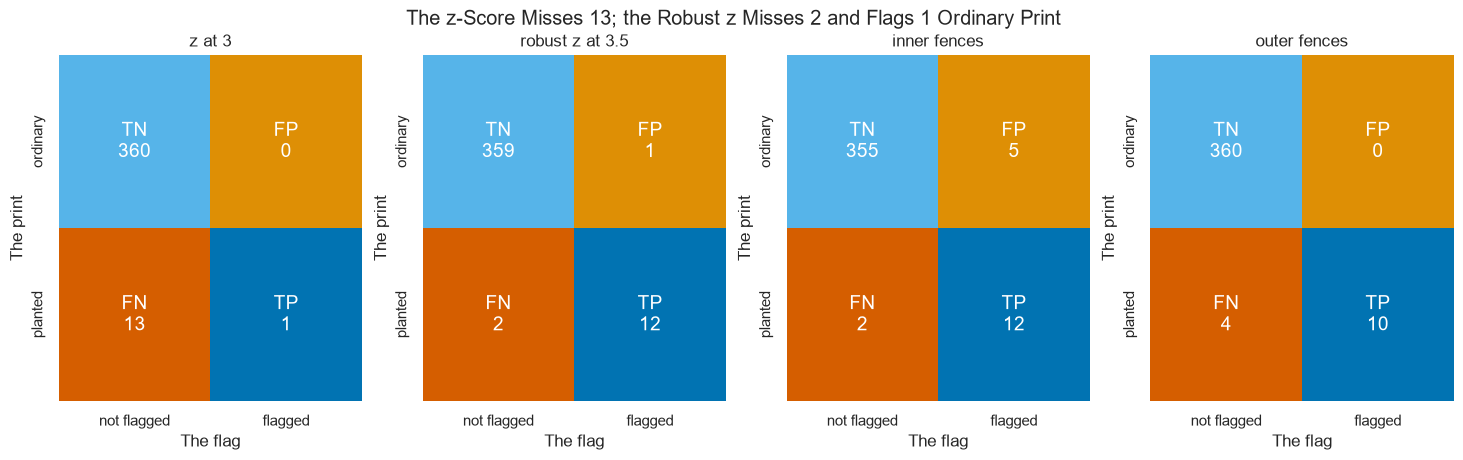

In [36]:
# draw a confusion matrix: each cell in its own colour, with its name and its count
def draw_confusion(flags, ax, title):
    tn, fp, fn, tp = confusion_matrix(planted, flags).ravel()
    labels = [[f"TN\n{tn}", f"FP\n{fp}"], [f"FN\n{fn}", f"TP\n{tp}"]]
    sns.heatmap([[0, 1], [2, 3]], cmap=list(CELL_COLOURS.values()), annot=labels, fmt="", cbar=False, ax=ax, annot_kws={"size": 14},
                xticklabels=["not flagged", "flagged"], yticklabels=["ordinary", "planted"])
    ax.set(xlabel="The flag", ylabel="The print", title=title)

# the four screens' confusion matrices
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
for ax, (name, flags) in zip(axes, screens.items()):
    draw_confusion(flags, ax, name)
fig.suptitle("The z-Score Misses 13; the Robust z Misses 2 and Flags 1 Ordinary Print")
plt.show()

In [37]:
# the two planted prints the robust z misses
missed = planted & ~robust_flags
planted_table.loc[missed].assign(distance=distance[missed].round(3), robust_z=robust_z[missed].round(2))

,trade_id,trade_date,issuer,duration,true_price,planted_price,kind,distance,robust_z
158,T0159,2026-09-15,Zephiskan Resources,7.565,94.024,92.414,off-market,-0.164,-1.84
314,T0315,2026-09-25,Bezoquil Freight,12.113,91.919,89.533,off-market,-0.225,-2.53


### Interpretation of the Four Screens

The robust z and the inner fences each find 12 of 14; the inner fences pay with 5 ordinary prints flagged.

The outer fences flag nothing ordinary and find 10.

T0159 and T0315 moved 1.6 and 2.4 points on bonds of 7.6 and 12.1 years, so per year of duration they sit near the ordinary prints.

**Predict 3**

The z-score at 3 found 1 of the 14.

Q. Lower its threshold as far as 1.5: at best, how many of the 14 does it find? Write down a number.

## Moving the Threshold

In [38]:
# both scores at every threshold from 1.5 to 8 in steps of 0.25
thresholds = np.arange(1.5, 8.01, 0.25)
results = []
for threshold in thresholds:
    results.append(screen_performance(z.abs() > threshold, planted).assign(screen="z", threshold=threshold))
    results.append(screen_performance(robust_z.abs() > threshold, planted).assign(screen="robust z", threshold=threshold))
sweep = pd.concat(results, ignore_index=True)

In [39]:
# the z-score's best, and the slipped prints' z-scores
z_sweep = sweep[sweep["screen"] == "z"]
best = z_sweep["Planted Found"].max()
print("The z-score finds at most", best, "of the 14, at thresholds", z_sweep.loc[z_sweep["Planted Found"] == best, "threshold"].tolist())
print("z of the 4 slipped prints:", z[slipped].round(3).tolist())

The z-score finds at most 3 of the 14, at thresholds [1.5, 1.75, 2.0]
z of the 4 slipped prints: [-18.975, -1.335, -2.145, -2.173]


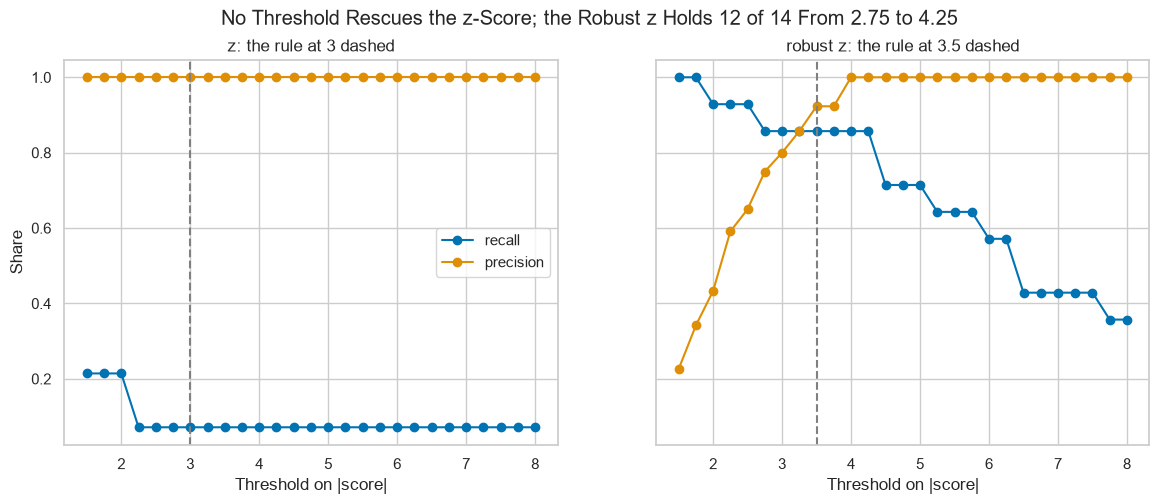

In [40]:
# recall and precision against the threshold, one panel a score
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, screen, rule in zip(axes, ["z", "robust z"], [3, 3.5]):
    part = sweep[sweep["screen"] == screen]
    ax.plot(part["threshold"], part["Recall"], marker="o", label="recall")
    ax.plot(part["threshold"], part["Precision"], marker="o", label="precision")
    ax.axvline(rule, color="gray", linestyle="--")
    ax.set(xlabel="Threshold on |score|", title=f"{screen}: the rule at {rule} dashed")
axes[0].set_ylabel("Share")
axes[0].legend()
fig.suptitle("No Threshold Rescues the z-Score; the Robust z Holds 12 of 14 From 2.75 to 4.25")
plt.show()

The z-score's best is 3 of the 14, at 1.5 to 2.0, and all three are slipped decimals: the biggest one stretched the sd that scores the rest.

The robust z finds 12 of 14 from 2.75 to 4.25, and every flag is planted from 4.0 up.

## Your Turn: Set the Threshold

In [41]:
# every print's |robust z| on a log axis, coloured by its confusion-matrix cell at a threshold
def draw_threshold(threshold=3.5):
    flags = robust_z.abs() > threshold
    cells = np.where(flags, np.where(planted, "TP", "FP"), np.where(planted, "FN", "TN"))
    plt.figure(figsize=(14, 5))
    for cell in ["TN", "FP", "FN", "TP"]:
        plt.scatter(trade_number[cells == cell], robust_z.abs()[cells == cell], s=25, color=CELL_COLOURS[cell], label=cell)
    plt.axhline(threshold, color="gray", linestyle="--")
    plt.yscale("log")
    plt.xlabel("Trade, in time order")
    plt.ylabel("|robust z| (log scale)")
    plt.legend(loc="upper left")
    plt.title(f"At {threshold}: {flags.sum()} Flags, {(flags & planted).sum()} of 14 Planted Found")
    plt.show()

In [42]:
# your turn: move the threshold and watch the four cells trade places
interact(draw_threshold, threshold=(1.5, 8.0, 0.25));

interactive(children=(FloatSlider(value=3.5, description='threshold', max=8.0, min=1.5, step=0.25), Output()),…

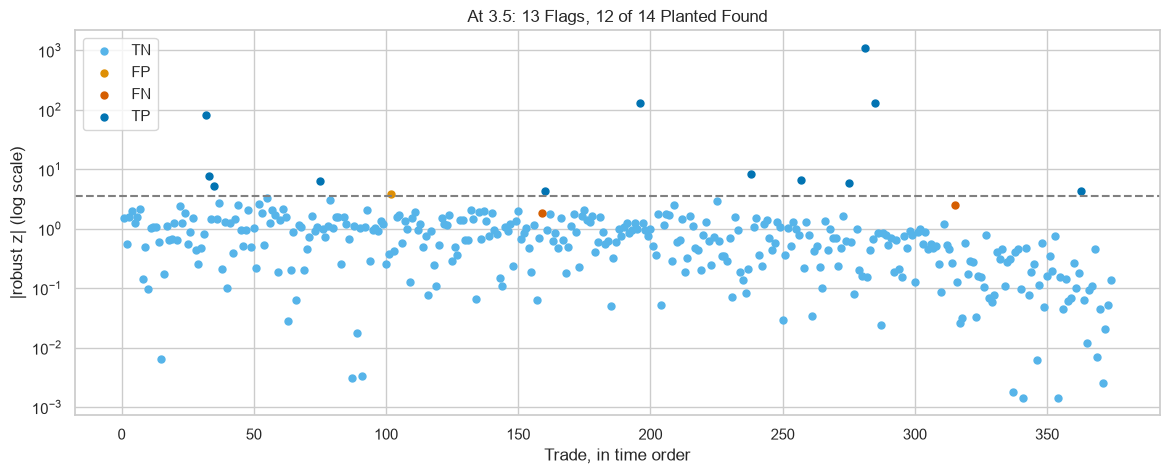

In [43]:
# the slider's starting position, drawn as a still picture (sliders do not run on GitHub)
draw_threshold(threshold=3.5)

**The labels score each threshold; a blotter without labels uses a threshold written down before the data, as today's 3.5.**

# Scoring Each Trade Against the Past

## The Trades Before Each Trade

The month's median and MAD read trades booked after each one, which a desk checking a print that morning could not see.
A trailing window (Course 3's notebook 07) of the 60 trades before each trade uses only the past: `.rolling(60).median()`, then `.shift(1)` so a trade never sits in its own window, the window Course 5B's Day 8 drew.
`.rolling(60).apply(f)` runs a function `f` on each window.

In [44]:
# each trade's median and MAD from the 60 trades before it
past_median = distance.rolling(60).median().shift(1)
past_mad = distance.rolling(60).apply(lambda window_values: (window_values - window_values.median()).abs().median()).shift(1)
rolling_scaled = 1.4826 * past_mad
rolling_z = (distance - past_median) / rolling_scaled

## The Cut Test

Course 5B's Day 2 strict cut test: blank every distance from T0200 (2026-09-17) on, recompute, and compare the rows up to and including the cut.
The trades run in time order, so a later trade on the same date sits after the cut.

In [45]:
# blank from row 199 (T0200) on, recompute the past median and MAD, and compare the first 200 rows
cut = 199
blanked = distance.copy()
blanked.iloc[cut:] = np.nan
cut_median = blanked.rolling(60).median().shift(1)
cut_mad = blanked.rolling(60).apply(lambda window_values: (window_values - window_values.median()).abs().median()).shift(1)
print("Past median unchanged:", cut_median.iloc[:cut + 1].equals(past_median.iloc[:cut + 1]))
print("Past MAD unchanged:", cut_mad.iloc[:cut + 1].equals(past_mad.iloc[:cut + 1]))

Past median unchanged: True
Past MAD unchanged: True


In [46]:
# the whole-month robust z on the first 200 trades alone, against the month's
first = distance.iloc[:cut + 1]
first_z = (first - first.median()) / (1.4826 * (first - first.median()).abs().median())
print("Median of the first 200:", round(first.median(), 4), "| of the month:", round(median, 4))
print("Robust z values that move:", (first_z != robust_z.iloc[:cut + 1]).sum(), "of", cut + 1)

Median of the first 200: -0.007 | of the month: -0.0012
Robust z values that move: 200 of 200


The rolling score passes: nothing after the cut reaches a trade before it.

The whole-month score moves every one of the 200 values once the later trades are gone.

## Rolling Flags

In [47]:
# the trades with a full window, and the rolling flags at 3.5
scored = rolling_z.notna()
rolling_flags = rolling_z.abs() > 3.5
print("Scored:", scored.sum(), "| planted among them:", (planted & scored).sum(), "| planted left unscored:", (planted & ~scored).sum())
print("The first scored trade:", prints.loc[scored.idxmax(), "trade_id"], "on", prints.loc[scored.idxmax(), "trade_date"])

Scored: 314 | planted among them: 11 | planted left unscored: 3
The first scored trade: T0061 on 2026-09-04


In [48]:
# the rolling score and the month's score on the same scored trades
both = pd.concat([screen_performance(rolling_flags[scored], planted[scored]),
                  screen_performance(robust_flags[scored], planted[scored])], ignore_index=True)
both.index = ["rolling, 60 before", "the whole month"]
both.round(3)

,Flags,Planted Found,Recall,Precision,F1
"rolling, 60 before",8,8,0.727,1.0,0.842
the whole month,10,9,0.818,0.9,0.857


The first 60 trades, T0001 to T0060, carry no score, and they hold 3 planted prints.

On the 314 scored trades the rolling screen flags only planted prints, 8 of 11; the month's score flags 10, 9 of them planted.

**Predict 4**

T0363, a planted print on 2026-09-30, scores 4.27 on the month's robust z.

Q. What does it score against the 60 trades before it? Write down a number.

## The Last Planted Print

In [49]:
# T0363's two scores, and its window's scaled MAD
last = prints["trade_id"] == "T0363"
print("Month robust z:", robust_z[last].round(2).iloc[0], "| rolling:", rolling_z[last].round(2).iloc[0],
      "| window's scaled MAD:", rolling_scaled[last].round(4).iloc[0])
print("Window's scaled MAD at trade 61:", round(rolling_scaled.iloc[60], 3), "| at trade 374:", round(rolling_scaled.iloc[373], 3))

Month robust z: 4.27 | rolling: 13.31 | window's scaled MAD: 0.0283
Window's scaled MAD at trade 61: 0.136 | at trade 374: 0.018


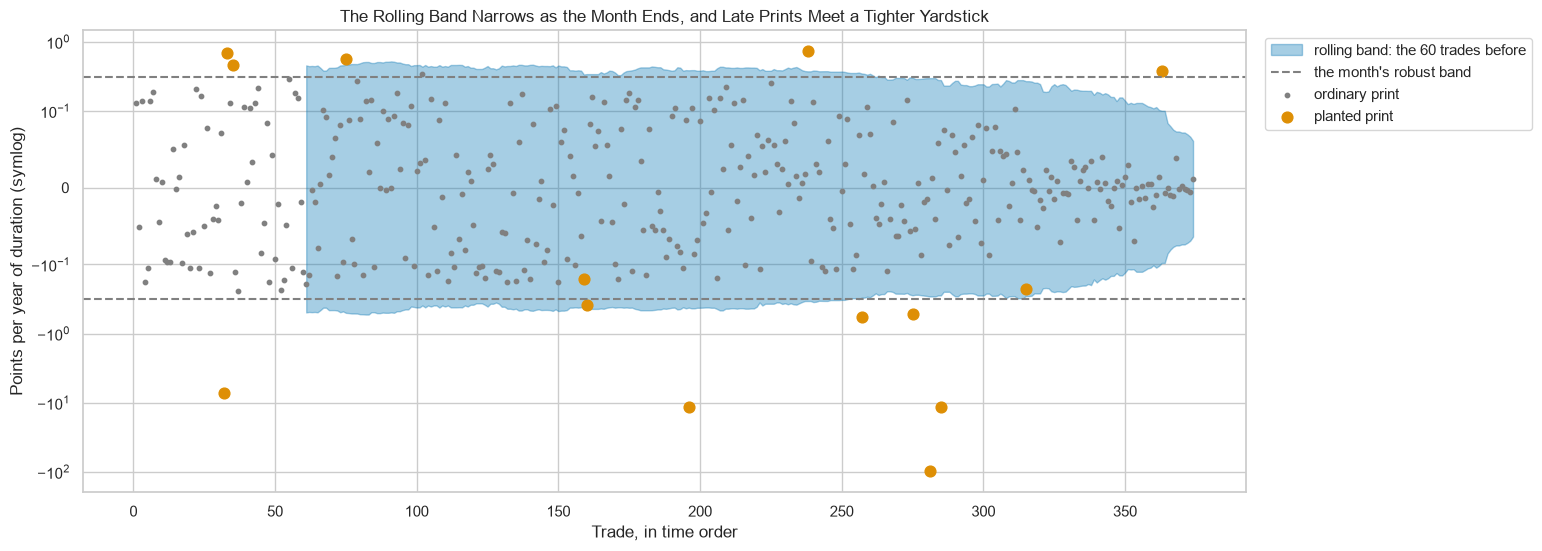

In [50]:
# the rolling band, past median plus or minus 3.5 rolling scaled MAD, beside the month's band
fig, ax = plt.subplots(figsize=(15, 6))
ax.fill_between(trade_number, past_median - 3.5 * rolling_scaled, past_median + 3.5 * rolling_scaled, color="C0", alpha=0.35, label="rolling band: the 60 trades before")
ax.axhline(robust_low, color="gray", linestyle="--", label="the month's robust band")
ax.axhline(robust_high, color="gray", linestyle="--")
ax.scatter(trade_number[~planted], distance[~planted], s=10, color="gray", label="ordinary print")
ax.scatter(trade_number[planted], distance[planted], s=60, color="C1", label="planted print")
ax.set_yscale("symlog", linthresh=0.1)
ax.set(xlabel="Trade, in time order", ylabel="Points per year of duration (symlog)", title="The Rolling Band Narrows as the Month Ends, and Late Prints Meet a Tighter Yardstick")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.show()

In [51]:
# T0160: flagged by the month's score, not by the rolling one
t0160 = prints["trade_id"] == "T0160"
print(prints.loc[t0160, "trade_date"].iloc[0], "| month:", robust_z[t0160].round(2).iloc[0], "| rolling:", rolling_z[t0160].round(2).iloc[0])

2026-09-15 | month: -4.33 | rolling: -3.27


The window's scaled MAD falls from 0.136 at trade 61 to 0.018 at trade 374, as the prints close in on the month-end price.

Late in the month the tighter window scores T0363 about three times higher; in the middle of it the rolling screen lets T0160 through, at -3.27.

**A rolling screen uses only what each trade could see, and its yardstick follows the month.**

# Insights and Conclusion

The planted prints, four slipped decimals above all, stretched the sd 57 times, and the z-score at 3 flagged 1 of 14.

No z threshold found more than 3.

The median and the scaled MAD barely moved; the robust z at 3.5 found 12 of 14 with 1 ordinary flag.

The inner fences found as many at lower precision, and the outer fences fewer with no ordinary flag.

One value at -10 took the sd from 0.090 to 0.525, while the IQR held until a quarter of the values were replaced and the MAD until half.

Prints sit closer to the month-end price as the month ends, and a 60-trade window follows that from the past alone.

Every flag is a print to check against the reference named, never a judgment on the trade.

**Measure the unusual with a yardstick the unusual cannot stretch.**

# Wrapping Up

## You Can Now

By the end of this notebook, you can:

* Measure a trade's distance from a reference price in points per year of duration.
* Plant labelled bad prints in a copy with a seeded generator, and keep the labels for scoring only.
* Score prints with a z-score, a robust z-score from the median and the scaled MAD, and Tukey's fences.
* Draw a sensitivity curve and find a yardstick's breakdown point.
* Score a screen by recall, precision and F1 against planted labels.
* Score each trade against a trailing window of the trades before it, and test it with the cut test.

## Exercises

Run this cell first: `check()` marks each answer as correct, not yet, or not attempted.

In [52]:
# check() compares your answer with the expected one
def check(label, answer, expected):
    if answer is ...:
        print(label + ": not attempted yet")
    elif isinstance(expected, float) and abs(answer - expected) < 1e-6:
        print(label + ": correct")
    elif answer == expected:
        print(label + ": correct")
    else:
        print(label + ": not yet. You have", answer)

### Exercise 1

**The Screen on a Clean Month**

Q. Run the robust z at 3.5 on the untouched month's distances, `trades["distance"]`, and store the number of flags in `ex1_flags`.

In [53]:
# the robust z on the untouched month, and the trades it flags
clean_median = clean.median()
clean_z = (clean - clean_median) / (1.4826 * (clean - clean_median).abs().median())
ex1_flags = int((clean_z.abs() > 3.5).sum())
print(ex1_flags)
trades.loc[clean_z.abs() > 3.5, ["trade_id", "trade_date", "issuer", "duration", "points"]]

2


,trade_id,trade_date,issuer,duration,points
54,T0055,2026-09-04,Vyrerone Metals,6.544,1.920
101,T0102,2026-09-09,Vyrellix Telecom,3.737,1.263


Two ordinary trades in the month's first nine days sit far from their month-end prices, and the file does not record why: what the screen costs on a clean month.

In [54]:
check("Exercise 1 the flags on the untouched month", ex1_flags, 2)

Exercise 1 the flags on the untouched month: correct


### Exercise 2

**A Rolling Function**

Q. Write `rolling_robust_z(values, window)`, which scores each value with the median and the scaled MAD of the `window` values before it, and store the number of flags above 3.5 on `distance` at a window of 20 in `ex2_flags`.

In [55]:
# each value scored against the window of values before it
def rolling_robust_z(values, window):
    """Each value's robust z against the median and scaled MAD of the window values before it."""
    centre = values.rolling(window).median().shift(1)
    spread = values.rolling(window).apply(lambda window_values: (window_values - window_values.median()).abs().median()).shift(1)
    return (values - centre) / (1.4826 * spread)

# at 20 trades, and at the lesson's 60 as a check
scores_20 = rolling_robust_z(distance, 20)
ex2_flags = int((scores_20.abs() > 3.5).sum())
print("Flags:", ex2_flags, "| planted:", ((scores_20.abs() > 3.5) & planted).sum(), "| scored:", scores_20.notna().sum(),
      "| flags at 60:", (rolling_robust_z(distance, 60).abs() > 3.5).sum())

Flags: 14 | planted: 12 | scored: 354 | flags at 60: 8


At 20 trades, 354 trades are scored and 12 of the 14 flags are planted; at the lesson's 60 the function gives its 8 again.

In [56]:
check("Exercise 2 the flags at a window of 20", ex2_flags, 14)

Exercise 2 the flags at a window of 20: correct


### Exercise 3

**Plain Points**

Q. Measure the copy's prints in plain points, `prints["price"] - trades["month_end_price"]`, with no duration, run the robust z at 3.5, and store the screen's precision against `planted` in `ex3_precision`.

In [57]:
# the robust z on plain points, scored against the planted labels
points = prints["price"] - trades["month_end_price"]
points_z = (points - points.median()) / (1.4826 * (points - points.median()).abs().median())
points_flags = points_z.abs() > 3.5
ex3_precision = precision_score(planted, points_flags)
print(ex3_precision)
screen_performance(points_flags, planted).round(3)

0.65


,Flags,Planted Found,Recall,Precision,F1
0,20,13,0.929,0.65,0.765


In [58]:
# the ordinary trades it flags, and their durations in years
print("Ordinary flags:", (points_flags & ~planted).sum(), "| durations:", trades.loc[points_flags & ~planted, "duration"].round(1).tolist())

Ordinary flags: 7 | durations: [12.9, 8.6, 6.5, 12.5, 12.9, 13.1, 13.1]


In plain points the long bonds' wider ordinary spread trips the screen: the ordinary flags are bonds of 6.5 to 13.1 years.

In [59]:
check("Exercise 3 the precision in plain points", ex3_precision, 0.65)

Exercise 3 the precision in plain points: correct


### Exercise 4: AI check

**Scores That Run Wide**

You asked an AI assistant for a function that returns robust z-scores.
This came back.
Test it against its docstring on normal draws, then find the one bug.

In [60]:
# written for this course in the style of an AI assistant's answer: it runs, and it has one bug
def robust_scores(values):
    """Robust z-scores: on normal data they have a standard deviation close to 1, like ordinary z-scores."""
    centre = values.median()
    spread = (values - centre).abs().median()
    return (values - centre) / spread

In [61]:
# the docstring's promise on 20,000 normal draws, and the flags it raises on the copy at 3.5
normal = pd.Series(np.random.default_rng(SEED).standard_normal(20_000))
print("sd of the scores on normal draws:", round(robust_scores(normal).std(), 3))
print("Flags on the copy:", (robust_scores(distance).abs() > 3.5).sum(), "| precision:", round(precision_score(planted, robust_scores(distance).abs() > 3.5), 3))

sd of the scores on normal draws: 1.496
Flags on the copy: 22 | precision: 0.591


Q. Fix the one wrong line, and store the fixed function's number of flags above 3.5 on `distance` in `ex4_flags`.

In [62]:
# the fix: scale the MAD by 1.4826, so the scores sit on the sd's scale
def robust_scores(values):
    """Robust z-scores: on normal data they have a standard deviation close to 1, like ordinary z-scores."""
    centre = values.median()
    spread = 1.4826 * (values - centre).abs().median()
    return (values - centre) / spread

ex4_flags = int((robust_scores(distance).abs() > 3.5).sum())
print(ex4_flags, "| sd on normal draws:", round(robust_scores(normal).std(), 3))

13 | sd on normal draws: 1.009


Without the 1.4826 the scores run about 1.48 times too wide, so a 3.5 threshold acts like 2.36 and flags 22 prints.

Scaled, the scores have an sd close to 1 on normal draws and give the lesson's 13 flags.

In [63]:
check("Exercise 4 the fixed function's flags", ex4_flags, 13)

Exercise 4 the fixed function's flags: correct


## Congratulations!

You planted bad prints in a month of trades and watched four of them hide the rest from the z-score.
You built a yardstick from the median and the MAD, and showed with a sliding print and a breakdown curve why it holds.
You scored four screens against labels they never saw, and moved a threshold to see what each one costs.
You also scored every trade against only the trades before it, the way a desk sees a print the morning it happens.
In Day 7 you screen many columns at once, with isolation forests and local outlier factors.

[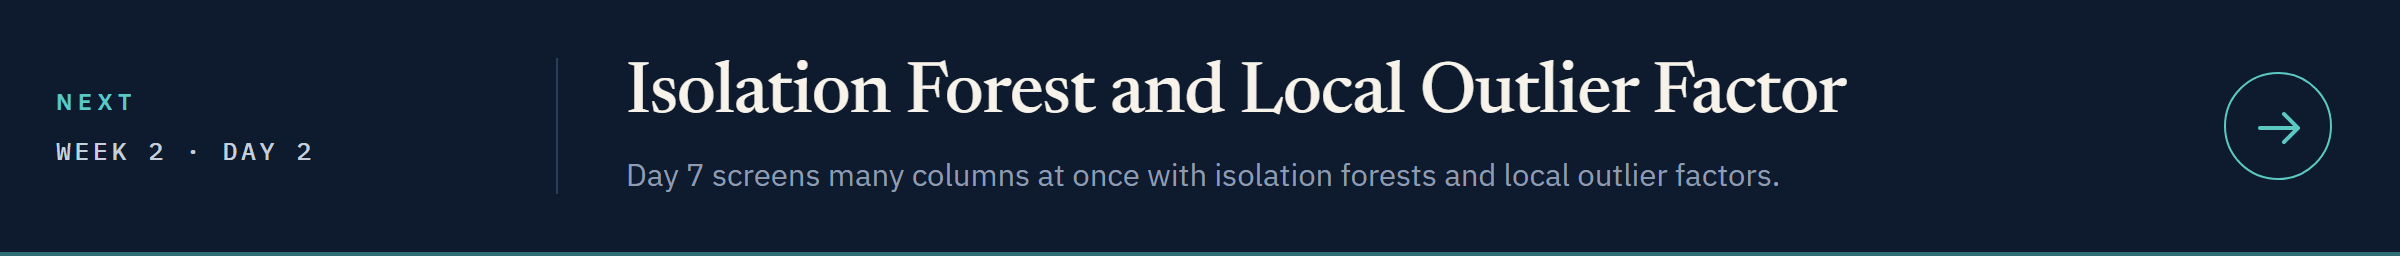](../day2/07_isolation_forest_and_local_outlier_factor.ipynb)

[Open Day 2 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course05c_risk_models/week2/day2/07_isolation_forest_and_local_outlier_factor.ipynb)